In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import warnings 
warnings.filterwarnings('ignore')

In [2]:
df= pd.read_csv('insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


<h1 style="color:red">EDA</h1>

In [3]:
df.shape

(1338, 7)

In [4]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [6]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [7]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [8]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

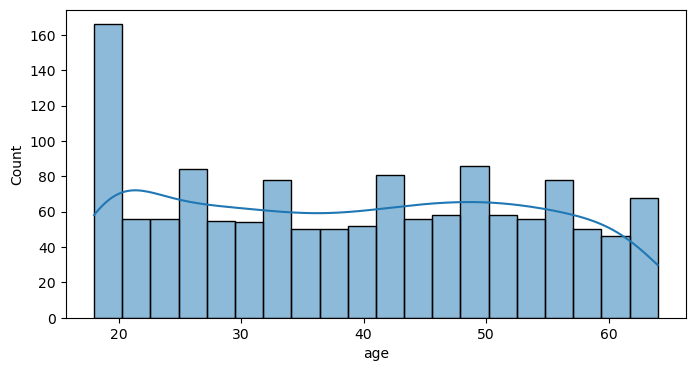

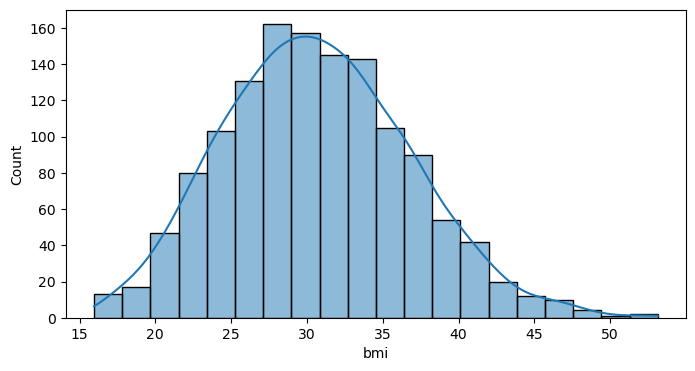

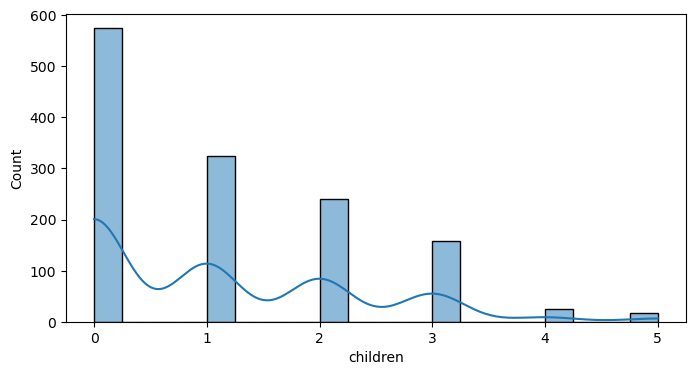

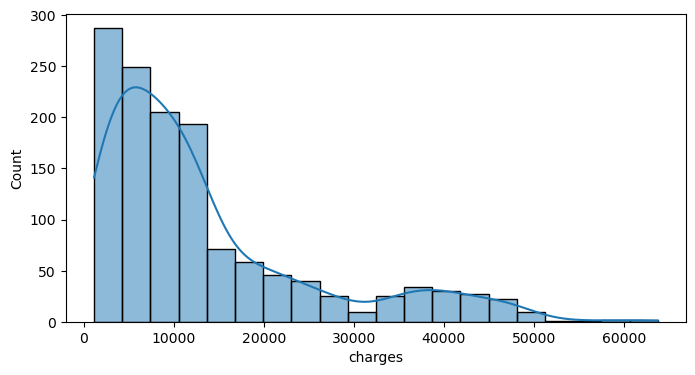

In [9]:
numeric_columns=['age', 'bmi', 'children', 'charges']

for cl in numeric_columns:
    plt.figure(figsize=(8,4))
    sns.histplot(df[cl],kde=True,bins=20)

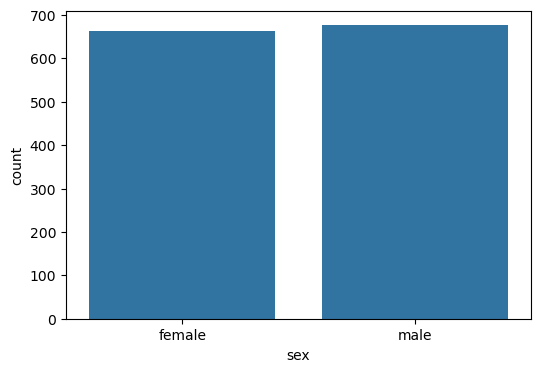

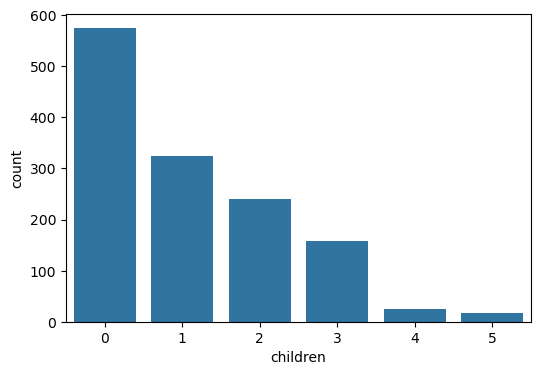

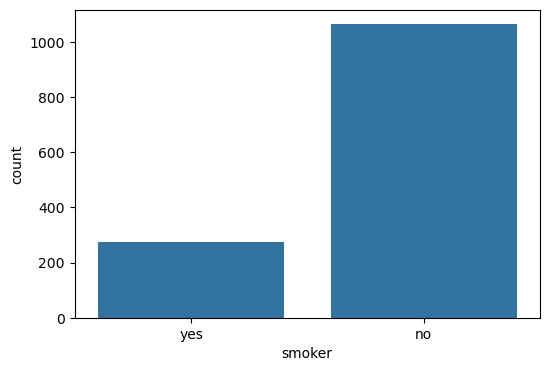

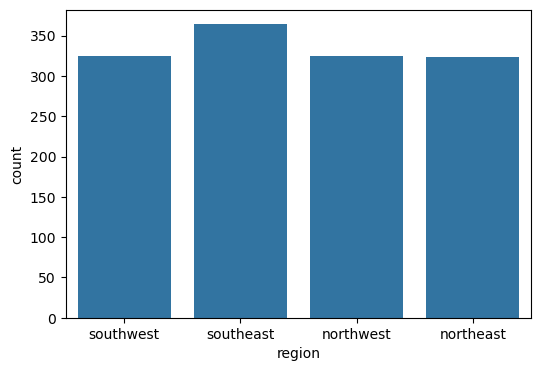

In [10]:
categorical_columns=[ 'sex', 'children', 'smoker', 'region',]
for cl in categorical_columns:
    plt.figure(figsize=(6,4))
    sns.countplot(x=df[cl])

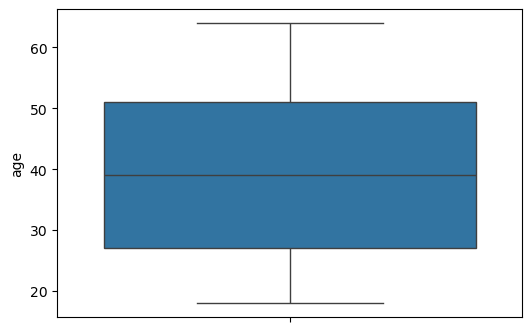

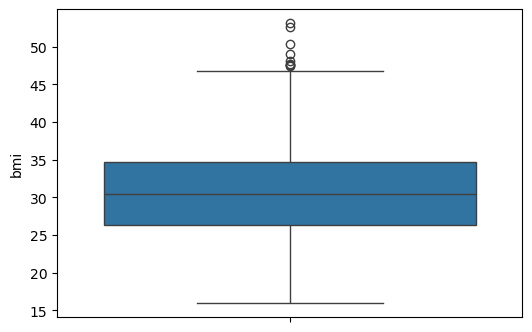

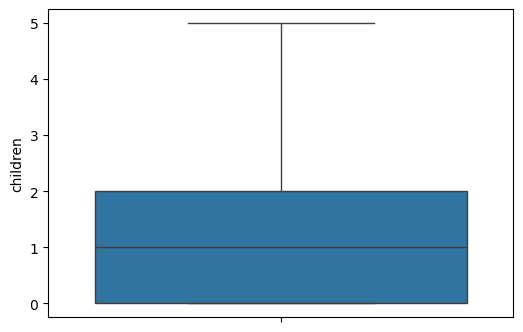

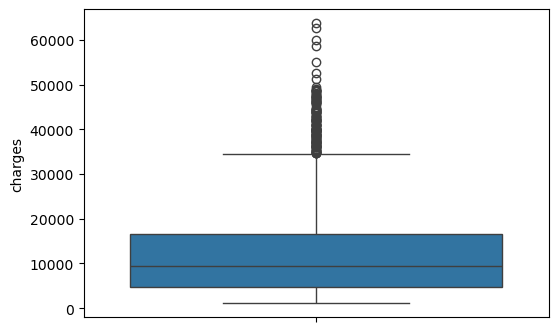

In [11]:
for cl in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(df[cl])

<Axes: >

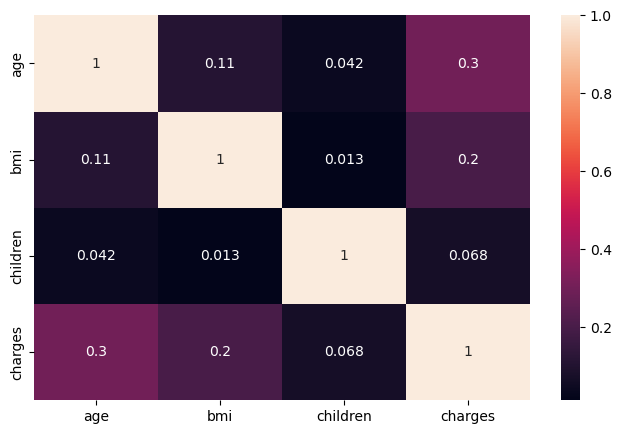

In [12]:
plt.figure(figsize=(8,5))
sns.heatmap(df.corr(numeric_only=True),annot=True)

<h1 style='color:green;'>Data Cleaning & Processing</h1>

In [13]:
df_cleaned=df.copy()
df_cleaned

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [14]:
df_cleaned.shape

(1338, 7)

In [15]:
df_cleaned.drop_duplicates(inplace=True)

In [16]:
df_cleaned.shape

(1337, 7)

In [17]:
df_cleaned.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [18]:
df_cleaned['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [19]:
df_cleaned["sex"]= df_cleaned["sex"].map({"male": 0, "female": 1})

In [20]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [21]:
df_cleaned["smoker"]= df_cleaned["smoker"].map({"no": 0, "yes": 1})

In [22]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [23]:
df_cleaned.rename(columns={
    "sex" : "is_male",
    "smoker" : "is_smoker"
},inplace= True)

In [24]:
df_cleaned.head()

,age,is_male,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [25]:
df_cleaned['region'].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

In [26]:
df_cleaned=pd.get_dummies(df_cleaned,columns=['region'],drop_first=False)
df_cleaned.head()

,age,is_male,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,False,True
1,18,0,33.770,1,0,1725.55230,False,False,True,False
2,28,0,33.000,3,0,4449.46200,False,False,True,False
3,33,0,22.705,0,0,21984.47061,False,True,False,False
4,32,0,28.880,0,0,3866.85520,False,True,False,False


In [27]:
df_cleaned=df_cleaned.astype(int)
df_cleaned.head(10)

,age,is_male,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,0,1
1,18,0,33,1,0,1725,0,0,1,0
2,28,0,33,3,0,4449,0,0,1,0
3,33,0,22,0,0,21984,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0
5,31,1,25,0,0,3756,0,0,1,0
6,46,1,33,1,0,8240,0,0,1,0
7,37,1,27,3,0,7281,0,1,0,0
8,37,0,29,2,0,6406,1,0,0,0
9,60,1,25,0,0,28923,0,1,0,0


<h1 style="color : orange ;">Feature Engineering & Extraction</h1>

<Axes: xlabel='bmi', ylabel='Count'>

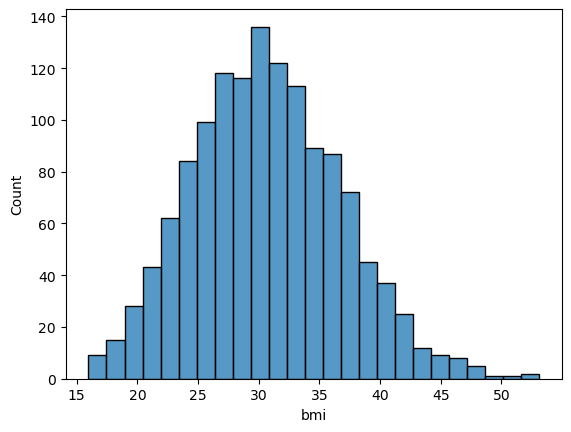

In [28]:
sns.histplot(df['bmi'])

In [29]:
df_cleaned['bmi_categories']= pd.cut(
    df_cleaned['bmi'],
    bins=[0, 18.5, 24.9, 29.9, float('inf')],
    labels=['Underweight','Normal','Overweight','Obese']
)

In [30]:
df_cleaned

,age,is_male,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_categories
0,19,1,27,0,1,16884,0,0,0,1,Overweight
1,18,0,33,1,0,1725,0,0,1,0,Obese
2,28,0,33,3,0,4449,0,0,1,0,Obese
3,33,0,22,0,0,21984,0,1,0,0,Normal
4,32,0,28,0,0,3866,0,1,0,0,Overweight
...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0,Obese
1334,18,1,31,0,0,2205,1,0,0,0,Obese
1335,18,1,36,0,0,1629,0,0,1,0,Obese
1336,21,1,25,0,0,2007,0,0,0,1,Overweight


In [31]:
df_cleaned=pd.get_dummies(df_cleaned,columns=['bmi_categories'],drop_first=False)
df_cleaned.head()

,age,is_male,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_categories_Underweight,bmi_categories_Normal,bmi_categories_Overweight,bmi_categories_Obese
0,19,1,27,0,1,16884,0,0,0,1,False,False,True,False
1,18,0,33,1,0,1725,0,0,1,0,False,False,False,True
2,28,0,33,3,0,4449,0,0,1,0,False,False,False,True
3,33,0,22,0,0,21984,0,1,0,0,False,True,False,False
4,32,0,28,0,0,3866,0,1,0,0,False,False,True,False


In [32]:
df_cleaned=df_cleaned.astype(int)
df_cleaned

,age,is_male,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_categories_Underweight,bmi_categories_Normal,bmi_categories_Overweight,bmi_categories_Obese
0,19,1,27,0,1,16884,0,0,0,1,0,0,1,0
1,18,0,33,1,0,1725,0,0,1,0,0,0,0,1
2,28,0,33,3,0,4449,0,0,1,0,0,0,0,1
3,33,0,22,0,0,21984,0,1,0,0,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,0,1,0,0,0,0,0,1
1334,18,1,31,0,0,2205,1,0,0,0,0,0,0,1
1335,18,1,36,0,0,1629,0,0,1,0,0,0,0,1
1336,21,1,25,0,0,2007,0,0,0,1,0,0,1,0


Feature scaling means bringing numerical features into a similar range so that one feature does not dominate another just because its numbers are much bigger.

Suppose your dataset has:

age = 25
bmi = 30
charges = 25000
Here, charges has much larger numbers than age and bmi.

Some machine learning algorithms may think:

“Charges is more important because its value is 25000.”

But a bigger number does not automatically mean a more important feature.

Feature scaling changes the values into a similar scale.

For example:

Before scaling:
age = 25
bmi = 30
income = 50000
After scaling, it might become something like:

age = 0.35
bmi = 0.42
income = 0.60
The meaning of the data stays the same, but the numerical ranges become more balanced.

Why do we perform feature scaling?
The main reason is to make sure that large-number features do not overpower small-number features.

For example, imagine a model uses distance.

Person A:

age = 20
salary = 20,000
Person B:

age = 40
salary = 80,000
The salary difference is:

60,000
The age difference is only:

20
Without scaling, the algorithm may mostly focus on salary because 60,000 is huge compared with 20.

After scaling, both features get a fair chance to affect the model.

Two common types of feature scaling
1. Standardization

Usually done with:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df[['age', 'bmi']] = scaler.fit_transform(df[['age', 'bmi']])

It transforms the data so that:

Mean ≈ 0
Standard deviation ≈ 1
Values may look like:

-1.2
-0.3
0.5
1.4
This is very commonly used.

2. Normalization / Min-Max Scaling

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df[['age', 'bmi']] = scaler.fit_transform(df[['age', 'bmi']])

It usually changes values to a range between:

0 and 1
For example:

Age:
18 → 0.00
30 → 0.25
45 → 0.56
64 → 1.00
Which algorithms need scaling?
Scaling is especially important for algorithms that care about distance or magnitude, such as:

K-Nearest Neighbors (KNN)
K-Means
Support Vector Machine (SVM)
Logistic Regression
Linear Regression in many cases
Neural Networks
It is usually not necessary for tree-based algorithms such as:

Decision Tree
Random Forest
XGBoost
A simple way to remember it is:

Feature scaling makes different numerical columns play on a similar numerical field.

In [33]:
from sklearn.preprocessing import StandardScaler

cols = ['age', 'bmi', 'children']

scaler = StandardScaler()

df_cleaned[cols] = scaler.fit_transform(df_cleaned[cols])

In [34]:
df_cleaned.head()

,age,is_male,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_categories_Underweight,bmi_categories_Normal,bmi_categories_Overweight,bmi_categories_Obese
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,0,1,0,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,0,1,0,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449,0,0,1,0,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,1,0,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,1,0,0,0,0,1,0


In [35]:
from sklearn.preprocessing import MinMaxScaler

cols=['age', 'bmi', 'children']

Scaler=MinMaxScaler()

df_cleaned[cols]=Scaler.fit_transform(df_cleaned[cols])

In [36]:
df_cleaned.head()

,age,is_male,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_categories_Underweight,bmi_categories_Normal,bmi_categories_Overweight,bmi_categories_Obese
0,0.021739,1,0.315789,0.0,1,16884,0,0,0,1,0,0,1,0
1,0.000000,0,0.473684,0.2,0,1725,0,0,1,0,0,0,0,1
2,0.217391,0,0.473684,0.6,0,4449,0,0,1,0,0,0,0,1
3,0.326087,0,0.184211,0.0,0,21984,0,1,0,0,0,1,0,0
4,0.304348,0,0.342105,0.0,0,3866,0,1,0,0,0,0,1,0


In [37]:
from scipy.stats import pearsonr

selected_features = [
    'age', 'bmi', 'children', 'is_male', 'is_smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_categories_Normal', 'bmi_categories_Overweight', 'bmi_categories_Obese'
]

correlations = {
    feature: pearsonr(df_cleaned[feature], df_cleaned['charges'])[0]
    for feature in selected_features
}
correlation_df = pd.DataFrame(list(correlations.items()), columns=['Feature', 'Pearson Correlation'])
correlation_df.sort_values(by='Pearson Correlation', ascending=False)

,Feature,Pearson Correlation
4,is_smoker,0.787234
0,age,0.298309
10,bmi_categories_Obese,0.200348
1,bmi,0.196236
6,region_southeast,0.073577
2,children,0.067390
5,region_northwest,-0.038695
7,region_southwest,-0.043637
3,is_male,-0.058046
8,bmi_categories_Normal,-0.104042


In [39]:
cat_features = [
    'is_male', 'is_smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_categories_Normal', 'bmi_categories_Overweight', 'bmi_categories_Obese'
]

In [40]:
from scipy.stats import chi2_contingency
import pandas as pd

alpha = 0.05

df_cleaned['charges_bin'] = pd.qcut(df_cleaned['charges'], q=4, labels=False)
chi2_results = {}

for col in cat_features:
    contingency = pd.crosstab(df_cleaned[col], df_cleaned['charges_bin'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'
    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    }

chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')
chi2_df

,chi2_statistic,p_value,Decision
is_smoker,848.219178,0.0,Reject Null (Keep Feature)
region_southeast,15.998167,0.001135,Reject Null (Keep Feature)
is_male,10.258784,0.01649,Reject Null (Keep Feature)
bmi_categories_Obese,8.515711,0.036473,Reject Null (Keep Feature)
region_southwest,5.091893,0.165191,Accept Null (Drop Feature)
bmi_categories_Overweight,4.25149,0.235557,Accept Null (Drop Feature)
bmi_categories_Normal,3.708088,0.29476,Accept Null (Drop Feature)
region_northwest,1.13424,0.768815,Accept Null (Drop Feature)


In [45]:
final_df = df_cleaned[['age', 'is_male', 'bmi', 'children', 'is_smoker', 'charges','region_southeast','bmi_categories_Obese']]

In [46]:
final_df

,age,is_male,bmi,children,is_smoker,charges,region_southeast,bmi_categories_Obese
0,0.021739,1,0.315789,0.0,1,16884,0,0
1,0.000000,0,0.473684,0.2,0,1725,1,1
2,0.217391,0,0.473684,0.6,0,4449,1,1
3,0.326087,0,0.184211,0.0,0,21984,0,0
4,0.304348,0,0.342105,0.0,0,3866,0,0
...,...,...,...,...,...,...,...,...
1333,0.695652,0,0.394737,0.6,0,10600,0,1
1334,0.000000,1,0.421053,0.0,0,2205,0,1
1335,0.000000,1,0.552632,0.0,0,1629,1,1
1336,0.065217,1,0.263158,0.0,0,2007,0,0
